# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import os
import re
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
# Load the CSV file from the same folder as this notebook
dataset_path = "Lab_11_QnA_Dataset.csv"
if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Dataset not found: {dataset_path}. "
        "Place the CSV file in the same folder as this notebook."
    )

df = pd.read_csv(dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from collections import Counter

# 1. Lowercase and remove punctuation
df["question"] = df["question"].astype(str).str.lower()
df["question"] = df["question"].apply(
    lambda text: re.sub(r"[^a-z0-9\s]", "", text)
)

# 2. Tokenization: give each word a number (0 is reserved for padding)
word_counts = Counter(word for question in df["question"] for word in question.split())
word_index = {word: index + 1 for index, (word, _) in enumerate(word_counts.items())}

# Convert each question to a sequence of word numbers
sequences = [
    [word_index[word] for word in question.split()]
    for question in df["question"]
]

# 3. Make all questions the same length by adding zeros (padding)
max_length = max(len(sequence) for sequence in sequences)
X = torch.tensor(
    [sequence + [0] * (max_length - len(sequence)) for sequence in sequences],
    dtype=torch.long
)

# Answers
y = torch.tensor(df["answer_id"].values, dtype=torch.long)

print("Vocabulary size:", len(word_index))
print("Input tensor shape:", X.shape)

Vocabulary size: 226
Input tensor shape: torch.Size([168, 11])


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        # Read each question as a batch-first sequence
        outputs, _ = self.rnn(self.emb(x))

        # Do not assign attention to padding tokens
        mask = (x != 0)
        scores = self.att(outputs).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=1)

        # Weighted sum of the RNN outputs
        context = (outputs * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

model.train()
for epoch in range(100):
    optimizer.zero_grad()
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()

print("Training finished!")
print(f"Final training loss: {loss.item():.4f}")

Training finished!
Final training loss: 0.0046


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

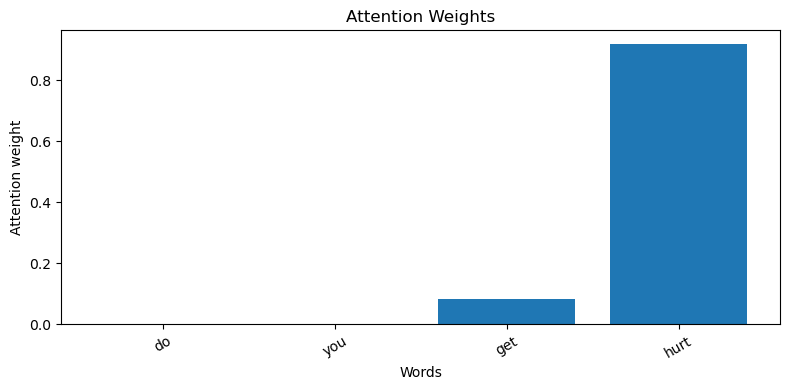

In [7]:
# Display attention for the first question (original Step 6 example)
model.eval()
question = df["question"].iloc[0]
words = question.split()
with torch.no_grad():
    prediction, weights = model(X[:1])

plt.figure(figsize=(8, 4))
plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.xlabel("Words")
plt.ylabel("Attention weight")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

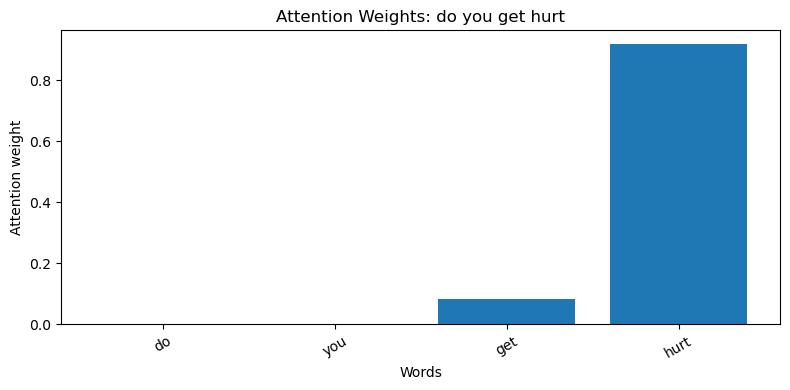

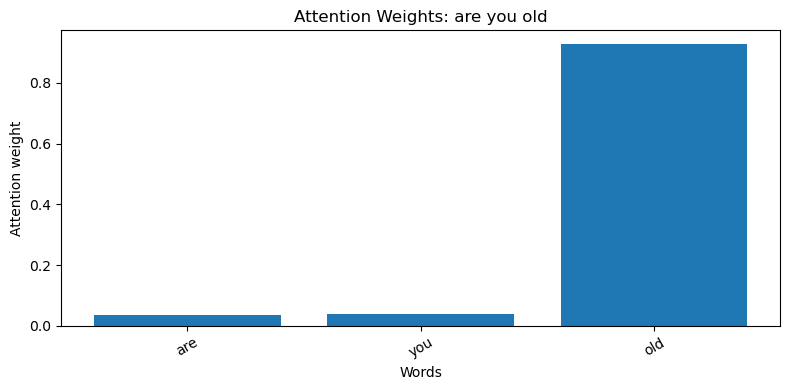

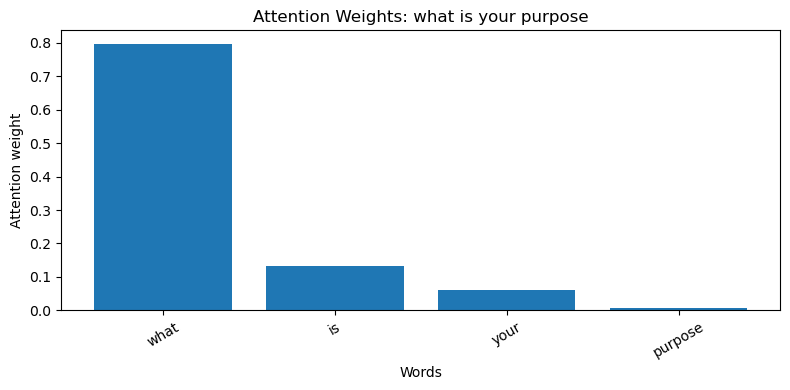

Word with the highest attention in each question:
Question: "do you get hurt" | Highest-attention word: "hurt" (0.919)
Question: "are you old" | Highest-attention word: "old" (0.926)
Question: "what is your purpose" | Highest-attention word: "what" (0.797)


In [8]:
# Task 1 — Visualize attention for three questions

# Select three questions from different answer groups
selected_indices = [0, 14, 70]

model.eval()
task1_top_words = []

for idx in selected_indices:
    question_text = df.loc[idx, "question"]
    words = question_text.split()
    with torch.no_grad():
        logits, attention_weights = model(X[idx:idx + 1])

    word_weights = attention_weights[0, :len(words)].cpu().tolist()
    top_position = int(torch.tensor(word_weights).argmax().item())
    top_word = words[top_position]
    task1_top_words.append((question_text, top_word, word_weights[top_position]))

    plt.figure(figsize=(8, 4))
    plt.bar(words, word_weights)
    plt.title(f"Attention Weights: {question_text}")
    plt.xlabel("Words")
    plt.ylabel("Attention weight")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

print("Word with the highest attention in each question:")
for question_text, top_word, weight in task1_top_words:
    print(f'Question: "{question_text}" | Highest-attention word: "{top_word}" ({weight:.3f})')

**Task 1 — Observation / Answer**

The word with the highest attention weight is the word the model uses most strongly in its weighted representation for that question. In many cases, this may be a meaningful word that helps distinguish the topic (for example, a word about age, purpose, or the body). However, attention weights do not prove that a word is always the most important to a person, and the highest-weight word can vary with the training data and model.

**Task 2 — Compare Attention for Similar Questions Medium**

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

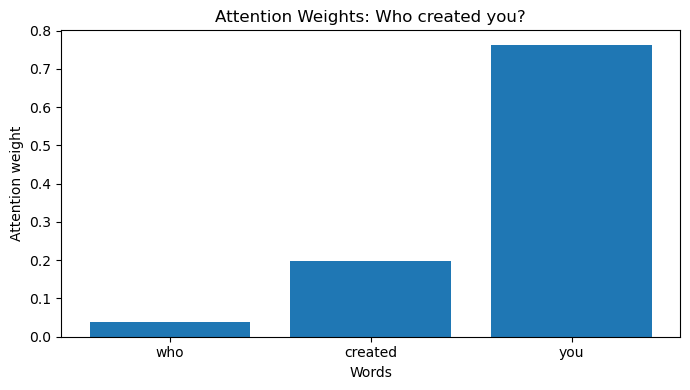

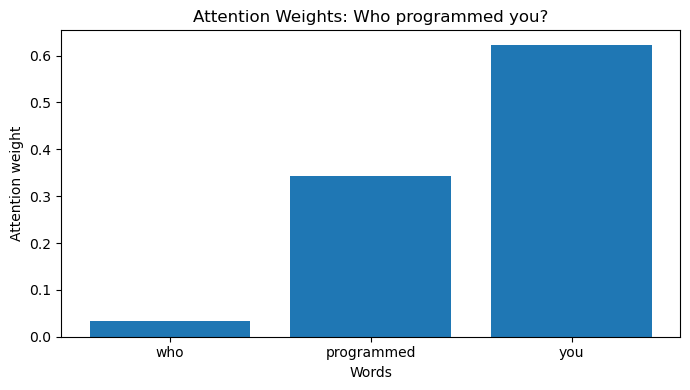

Comparison:
"Who created you?" -> highest-attention word: "you"
"Who programmed you?" -> highest-attention word: "you"


In [9]:
# Task 2 — Compare attention for two similarly meaning questions

# These two questions belong to the same answer group (answer_id = 3)
similar_questions = ["Who created you?", "Who programmed you?"]

model.eval()
task2_results = []

for question_text in similar_questions:
    cleaned = re.sub(r"[^a-z0-9\s]", "", question_text.lower())
    sequence = [[word_index[word] for word in cleaned.split() if word in word_index]]
    token_ids = sequence[0][:X.shape[1]]
    padded = token_ids + [0] * (X.shape[1] - len(token_ids))
    input_tensor = torch.tensor([padded], dtype=torch.long)

    with torch.no_grad():
        logits, attention_weights = model(input_tensor)

    words = cleaned.split()
    word_weights = attention_weights[0, :len(words)].cpu().tolist()
    top_word = words[int(torch.tensor(word_weights).argmax().item())]
    task2_results.append((words, word_weights, top_word))

    plt.figure(figsize=(7, 4))
    plt.bar(words, word_weights)
    plt.title(f"Attention Weights: {question_text}")
    plt.xlabel("Words")
    plt.ylabel("Attention weight")
    plt.tight_layout()
    plt.show()

print("Comparison:")
for question_text, result in zip(similar_questions, task2_results):
    print(f'"{question_text}" -> highest-attention word: "{result[2]}"')

**Task 2 — Observation / Answer**

The two questions have similar meanings and share the same answer group in the dataset, but their wording is different. Compare the printed highest-attention words and the two bar charts: the model may focus on related meaning-bearing words, or on different words because the exact wording and learned word representations differ. This suggests that attention assigns weights to the words in each input sequence; it does not automatically guarantee identical focus for paraphrases.

